In [8]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
#from ipynb.fs.full import utils  # optional, to import functions from *.ipynb files
from mintpy.utils import readfile, utils as ut, plot as pp
from mintpy.cli import view, tsview, plot_network, plot_transection
from mintpy.view import prep_slice, plot_slice
plt.rcParams.update({'font.size': 12})
from mintpy.objects import timeseries
import pandas as pd
import matplotlib.pyplot as plt
from mintpy.objects import ifgramStack
from mintpy.utils import network as pnet, ptime, readfile, utils0 as ut0

import shapefile as shp
from shapely.geometry import Point
from shapely.geometry import shape 
from sklearn.metrics import r2_score
import matplotlib
from matplotlib.colors import ListedColormap, BoundaryNorm

In [9]:
def calculate_rmse(actual_values, predicted_values):
    mse = np.mean((actual_values - predicted_values) ** 2)
    rmse = np.sqrt(mse)
    return rmse
fs = 16
files = os.listdir('./Results/Site_multi_try/')
csv_files = [file for file in files if file.endswith('.csv')]

In [10]:
pwd

'/Users/boyazhang/Documents/Work/California/Processing/SacFull'

In [11]:
res_mat = []
for i in range(len(csv_files)):
    result = pd.read_csv('./Results/Site_multi_try/' + csv_files[i], header=None)
    result = result.iloc[1:]
    #result = np.array(result)
    site = csv_files[i][5]
    site = int(site)
#     if (site < 5):
#         site = site + 1
    result.insert(loc=0, column='unit', value=site)
    res_mat.extend(result.values.tolist())
res_mat = np.array(res_mat)

In [12]:
dates = ['20170307', '20170319', '20170331', '20170412', '20170424', '20170506', '20170518', '20170530', '20170611', '20170623', '20170705', '20170717','20170729', '20170810','20170822', '20170903', '20170915', '20170927', '20171009']

In [13]:
dates = list(map(int, dates))
dateitem = res_mat[:, 2]
dateitem = list(map(float, dateitem))
indexes = [dates.index(item) for item in dateitem]
indexes = np.array(indexes)

0.9221809262331894
0.850417660708303


/var/folders/xc/0nh5gdkn5sz1hyvvnl87lbc00000gn/T/ipykernel_3243/3169856262.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_plasma = plt.cm.get_cmap('plasma', 6)  # 10 is the number of discrete colors


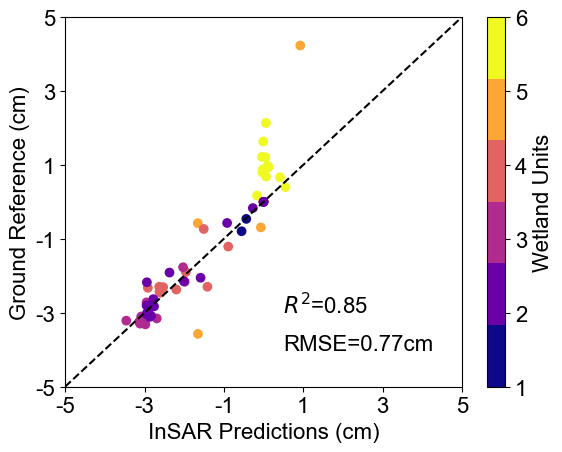

In [15]:
###################### Plot the figure ###############################
fig, ax = plt.subplots()

plt.rcParams['font.family'] = 'Arial'
pred = res_mat[:, 3].astype(float)
true = res_mat[:, 4].astype(float)
unit = res_mat[:, 0].astype(int)

for i in range(len(unit)):
    if unit[i] == 0:
        unit[i] = 1
    elif unit[i] == 4:
        unit[i] = 3
    elif unit[i] == 7:
        unit[i] = 4
    elif unit[i] == 8:
        unit[i] = 5
    elif unit[i] == 9:
        unit[i] = 6
        
cmap_plasma = plt.cm.get_cmap('plasma', 6)  # 10 is the number of discrete colors
cmap_discrete = ListedColormap(cmap_plasma(np.arange(cmap_plasma.N)))

#plt.scatter(pred, true)
scatter = plt.scatter(pred, true, c=unit, cmap=cmap_discrete)

# Set labels for the ticks
#colorbar.set_ticklabels([1, 2, 3, 4, 5 ,6])

# Create a scatter plot with discrete colorbar
#scatter = plt.scatter(pred, true, c=unit, cmap=cmap_discrete)

# Create a discrete colorbar
norm = BoundaryNorm(np.arange(-0.5, 6.5, 1), cmap_discrete.N)
colorbar = plt.colorbar(scatter, ticks=[1, 2, 3, 4, 5, 6], norm=norm)
colorbar.set_label('Wetland Units', fontsize=fs)
# Set labels for the ticks
colorbar.set_ticklabels([1, 2, 3, 4, 5, 6])
colorbar.ax.tick_params(labelsize=fs)  # Change the font size of the color bar label


plt.ylabel('Ground Reference (cm)', fontsize=fs)
plt.xlabel('InSAR Predictions (cm)', fontsize=fs)


plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
 
    
x = range(-5, 5)
ax.plot(range(-5, 6), range(-5, 6), label='', color = 'black',linestyle='--')

xtick_locations = [-5, -3,  -1, 1, 3, 5]
xtick_labels = ['-5', '-3', '-1', '1', '3', '5']

plt.xticks(xtick_locations, xtick_labels)
plt.yticks(xtick_locations, xtick_labels)

prednew = np.insert(pred, 0, -4.5)
prednew = np.insert(prednew, 59, 3)

coefficients = np.polyfit(pred, true, 1)  # 1 indicates a first-degree polynomial (linear regression)
best_fit_line = np.polyval(coefficients, prednew)

#plt.plot(prednew, best_fit_line, color='red', label='Best-Fit Line')
plt.xlim(-5, 5)
plt.ylim(-5, 5)

#plt.axis('equal')
# Add legend
#plt.legend(loc='upper left', fontsize=fs)
corr_coeff = np.corrcoef(pred, true)[0, 1]
# #plt.title('Y/X ' + str(lati) + ' ' + str(loni))
# #plt.title('lalo ' + str(lati) + ' ' + str(loni))
# plt.show()
r2 = corr_coeff * corr_coeff
print(corr_coeff)
print(r2)
rmse = calculate_rmse(pred, true)
plt.text(0.5, -3, r'$R^2$=' + f'{r2:.2f}', fontsize=fs, color='black')
plt.text(0.5, -4, r'RMSE=' + f'{rmse:.2f}' +'cm', fontsize=fs, color='black')
plt.savefig('scatter.tif', dpi=300, format='tiff',bbox_inches='tight')



In [18]:
pwd

'/Users/boyazhang/Documents/Work/California/Processing/SacFull'

In [14]:
len(np.insert(pred, 0, -4.5))

59

In [61]:
best_fit_line

array([-4.91302127,  0.53925521,  1.66008332,  0.45779699, -1.46866798,
       -1.46361069,  0.53925521,  0.33954923,  1.20611467,  1.04150559,
        0.65970811,  0.68249136,  0.61579306,  0.5138682 ,  0.50282916,
        0.68463229,  0.48928691,  0.6123557 ,  0.52842457,  0.59544152,
        0.53925521, -1.28711323, -0.53954675, -1.83452542, -2.63909484,
       -1.17466306, -2.12443993, -2.64670743, -2.52631632, -2.9932832 ,
       -2.61528778,  0.53925521, -1.87059163, -1.91820454, -2.7223814 ,
       -3.06882995, -3.03229485, -3.19772661, -3.6527518 , -3.25920406,
       -3.23216319,  0.53925521, -0.13155412,  0.01174867,  0.53925521,
        0.21159641, -0.57325879, -1.38376271, -1.89113944, -2.33292771,
       -2.89323635, -3.02038223, -2.94409277, -3.03286189, -2.98650542,
       -3.03326414, -3.02351305, -2.82608975, -2.80463201])

In [63]:
np.insert(pred, 3, -4.5)

array([ 0.      ,  0.925068, -0.067231, -4.5     , -1.657226, -1.653052,
        0.      , -0.164826,  0.550388,  0.414529,  0.099415,  0.118219,
        0.06317 , -0.020953, -0.030064,  0.119986, -0.041241,  0.060333,
       -0.008939,  0.046373,  0.      , -1.507381, -0.890382, -1.959184,
       -2.62323 , -1.414571, -2.198463, -2.629513, -2.530149, -2.915557,
       -2.603581,  0.      , -1.988951, -2.028248, -2.69197 , -2.977909,
       -2.947755, -3.084293, -3.459845, -3.135033, -3.112715,  0.      ,
       -0.553648, -0.435374,  0.      , -0.270431, -0.918206, -1.58715 ,
       -2.00591 , -2.370537, -2.832984, -2.937923, -2.874958, -2.948223,
       -2.909963, -2.948555, -2.940507, -2.777565, -2.759855])

In [23]:
matplotlib.use('Agg') 

In [ ]:
unit

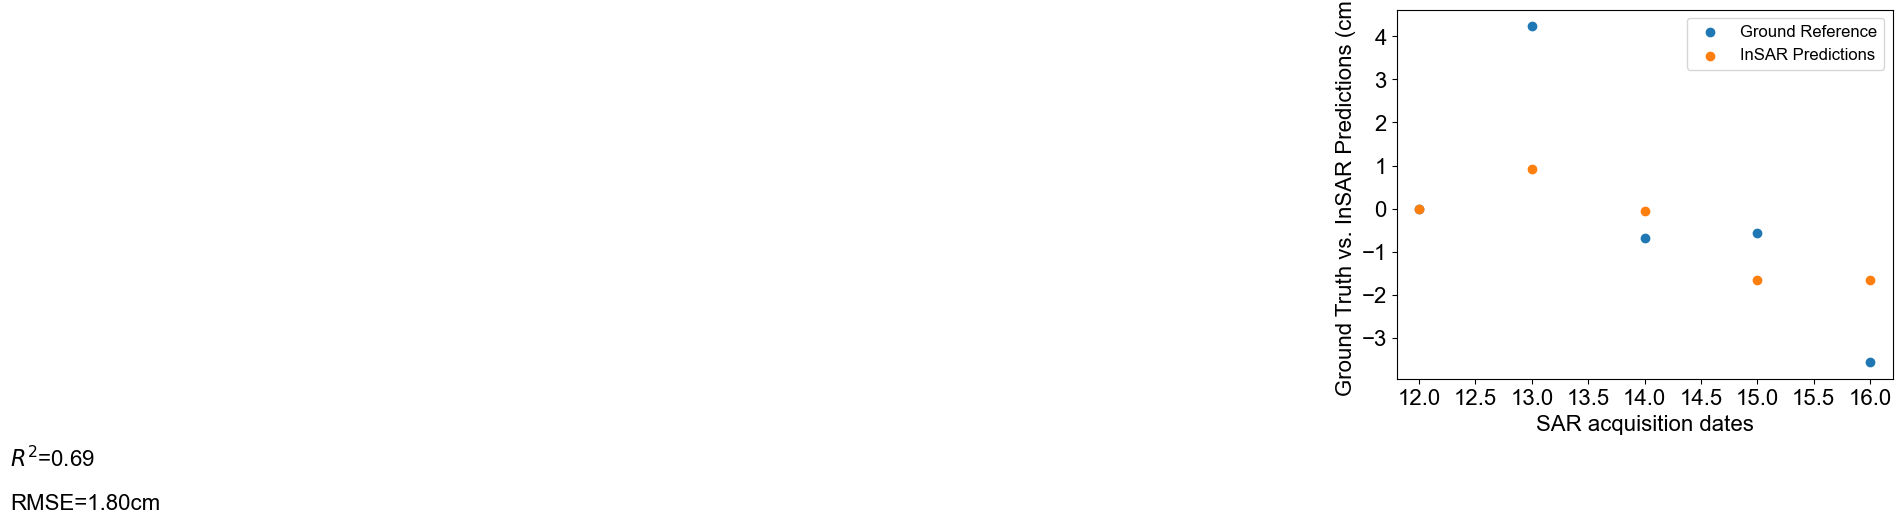

<Figure size 640x480 with 0 Axes>

In [8]:
fig, ax = plt.subplots()
#min_index = np.where(wetpix == 12538)[0]
#min_index = mini
wetind = 5
ID = range(len(dates))

plt.scatter(indexes[np.where(unit == wetind)[0]], true[np.where(unit == wetind)[0]], label = 'Ground Reference', linestyle='-')
plt.scatter(indexes[np.where(unit == wetind)[0]], pred[np.where(unit == wetind)[0]], label = 'InSAR Predictions', linestyle='-')

#ax.plot(ID, wdv, color='red', linestyle='-')
#ax.plot(ID, poic[int(min_index[0])], color='red', linestyle='-')

plt.xlabel('SAR acquisition dates', fontsize = fs)
plt.ylabel('Ground Truth vs. InSAR Predictions (cm)', fontsize = fs)
plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)

corr_coeff = np.corrcoef(true[np.where(unit == wetind)[0]], pred[np.where(unit == wetind)[0]])[0, 1]
#plt.title('Y/X ' + str(lati) + ' ' + str(loni))
#plt.title('lalo ' + str(lati) + ' ' + str(loni))

r2 = corr_coeff * corr_coeff
error = calculate_rmse(true[np.where(unit == wetind)[0]], pred[np.where(unit == wetind)[0]])
plt.text(-0.5, -6, r'$R^2$=' + f'{r2:.2f}', fontsize=fs, color='black')
plt.text(-0.5, -7, r'RMSE=' + f'{error:.2f}' +'cm', fontsize=fs, color='black')
# xltick = [dates[i] for i in ID]

# if len(ID) > 8:
#     ID = ID[::4]
#     xltick = xltick[::4]

# plt.xticks(ID, xltick)

#plt.title('Y/X ' + str(yo) + ' ' + str(xo) + ' RMSE = ' + str(errmin))
#plt.title('lalo ' + str(lati) + ' ' + str(loni) + ' RMSE = ' + str(errmin))

# Show the plot
plt.legend()
plt.show()
plt.savefig('plot.png')

In [ ]:
true[np.where(unit == wetind)[0]]